In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("Housing.csv")
print("Shape:", df.shape)
display(df.head())

Shape: (545, 13)


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [2]:
print(df.info())
display(df.describe())
print("Missing values:\n", df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())

features = ['area', 'bedrooms', 'bathrooms', 'stories', 'parking']
target = 'price'
df = df.drop_duplicates().dropna(subset=features + [target])
X, y = df[features], df[target]
print("Clean data shape:", df.shape)

<class 'pandas.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   price             545 non-null    int64
 1   area              545 non-null    int64
 2   bedrooms          545 non-null    int64
 3   bathrooms         545 non-null    int64
 4   stories           545 non-null    int64
 5   mainroad          545 non-null    str  
 6   guestroom         545 non-null    str  
 7   basement          545 non-null    str  
 8   hotwaterheating   545 non-null    str  
 9   airconditioning   545 non-null    str  
 10  parking           545 non-null    int64
 11  prefarea          545 non-null    str  
 12  furnishingstatus  545 non-null    str  
dtypes: int64(6), str(7)
memory usage: 55.5 KB
None


,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000


Missing values:
 price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64
Duplicate rows: 0
Clean data shape: (545, 13)


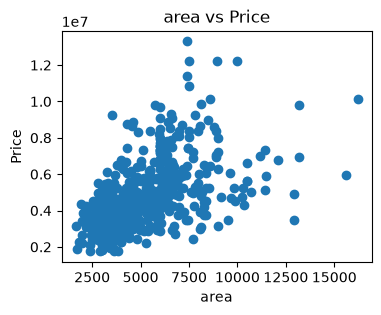

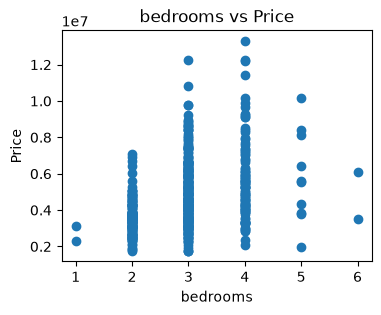

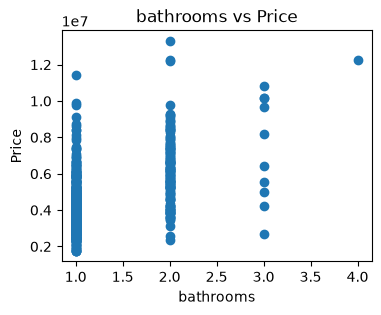

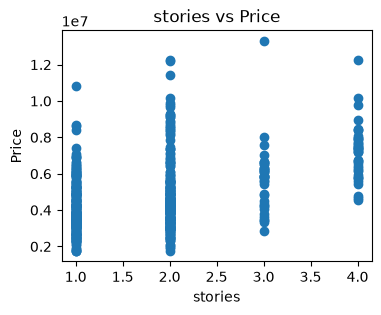

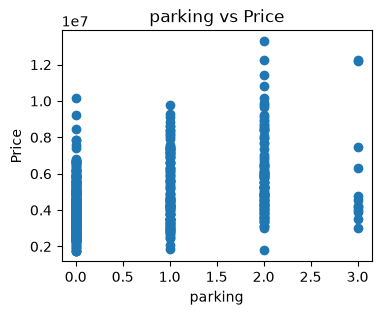

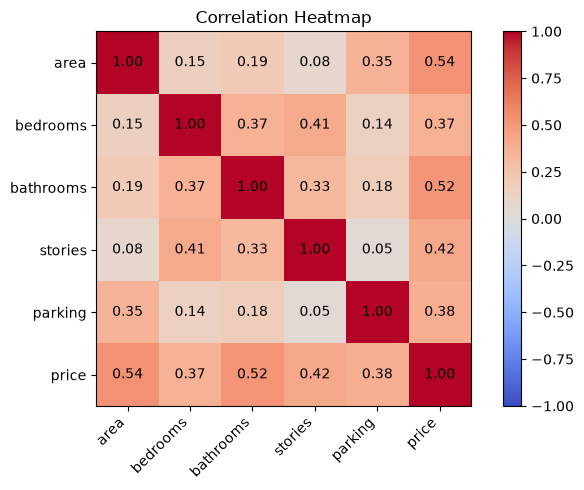

,area,bedrooms,bathrooms,stories,parking,price
area,1.000000,0.151858,0.193820,0.083996,0.352980,0.535997
bedrooms,0.151858,1.000000,0.373930,0.408564,0.139270,0.366494
bathrooms,0.193820,0.373930,1.000000,0.326165,0.177496,0.517545
stories,0.083996,0.408564,0.326165,1.000000,0.045547,0.420712
parking,0.352980,0.139270,0.177496,0.045547,1.000000,0.384394
price,0.535997,0.366494,0.517545,0.420712,0.384394,1.000000


In [3]:
for col in features:
    plt.figure(figsize=(4, 3))
    plt.scatter(df[col], y)
    plt.xlabel(col); plt.ylabel("Price"); plt.title(col + " vs Price")
    plt.show()

corr = df[features + [target]].corr()
plt.figure(figsize=(7, 5))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
plt.yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center")
plt.title("Correlation Heatmap"); plt.tight_layout(); plt.show()
display(corr)

In [4]:
s = df[['area', 'bedrooms', 'price']].head(6)
A = np.column_stack([np.ones(len(s)), s[['area', 'bedrooms']].values])
Y = s['price'].values
AT = A.T
ATA, ATY = AT @ A, AT @ Y
b = np.linalg.solve(ATA, ATY)

print("Sample:\n", s)
print("Design matrix X:\n", A)
print("Target vector y:", Y)
print("X transpose X:\n", ATA)
print("X transpose y:", ATY)
print("Manual coefficients [b0, b1, b2]:", b)
print("Predicted first price:", A[0] @ b)
print("First residual:", Y[0] - A[0] @ b)

check = LinearRegression().fit(s[['area', 'bedrooms']], Y)
print("Library coefficients:", check.intercept_, check.coef_)

Sample:
    area  bedrooms     price
0  7420         4  13300000
1  8960         4  12250000
2  9960         3  12250000
3  7500         4  12215000
4  7420         4  11410000
5  7500         3  10850000
Design matrix X:
 [[1.00e+00 7.42e+03 4.00e+00]
 [1.00e+00 8.96e+03 4.00e+00]
 [1.00e+00 9.96e+03 3.00e+00]
 [1.00e+00 7.50e+03 4.00e+00]
 [1.00e+00 7.42e+03 4.00e+00]
 [1.00e+00 7.50e+03 3.00e+00]]
Target vector y: [13300000 12250000 12250000 12215000 11410000 10850000]
X transpose X:
 [[6.00000e+00 4.87600e+04 2.20000e+01]
 [4.87600e+04 4.02096e+08 1.77580e+05]
 [2.20000e+01 1.77580e+05 8.20000e+01]]
X transpose y: [7.227500e+07 5.881057e+11 2.660000e+08]
Manual coefficients [b0, b1, b2]: [5.34523027e+06 3.47183900e+02 1.05795143e+06]
Predicted first price: 12153140.520673163
First residual: 1146859.4793268368
Library coefficients: 5345230.269393597 [3.47183900e+02 1.05795143e+06]


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
single = LinearRegression().fit(X_train[['area']], y_train)
multi = LinearRegression().fit(X_train, y_train)

print("Train rows:", len(X_train), "| Test rows:", len(X_test))
print("Single model intercept/coefficient:", single.intercept_, single.coef_)
print("Multiple model intercept:", multi.intercept_)
print(pd.DataFrame({'Feature': features, 'Coefficient': multi.coef_}))

Train rows: 436 | Test rows: 109
Single model intercept/coefficient: 2512254.2639593435 [425.72984194]
Multiple model intercept: 51999.67680883687
     Feature   Coefficient
0       area  3.088670e+02
1   bedrooms  1.512468e+05
2  bathrooms  1.185732e+06
3    stories  4.951008e+05
4    parking  3.376608e+05


In [6]:
equation = f"Price = {multi.intercept_:.2f}"
for name, value in zip(features, multi.coef_):
    equation += f" + ({value:.2f} x {name})"
print(equation)

scaler = StandardScaler().fit(X_train)
scaled = LinearRegression().fit(scaler.transform(X_train), y_train)
display(pd.DataFrame({'Feature': features,
                      'Standardised coefficient': scaled.coef_}))

Price = 51999.68 + (308.87 x area) + (151246.75 x bedrooms) + (1185731.71 x bathrooms) + (495100.76 x stories) + (337660.83 x parking)


,Feature,Standardised coefficient
0,area,680058.424141
1,bedrooms,112973.185629
2,bathrooms,565408.617936
3,stories,424354.811764
4,parking,288348.772668


In [7]:
pred = multi.predict(X_test)
results = pd.DataFrame({'Actual': y_test.values, 'Predicted': pred})
results['Residual'] = results['Actual'] - results['Predicted']
display(results.head(10))

,Actual,Predicted,Residual
0,4060000,6.178628e+06,-2.118628e+06
1,6650000,6.370141e+06,2.798591e+05
2,3710000,3.283148e+06,4.268518e+05
3,6440000,4.226008e+06,2.213992e+06
4,2800000,3.409686e+06,-6.096856e+05
5,4900000,4.262158e+06,6.378417e+05
6,5250000,5.493441e+06,-2.434405e+05
7,4543000,5.559898e+06,-1.016898e+06
8,2450000,3.373715e+06,-9.237154e+05
9,3353000,3.020513e+06,3.324868e+05


In [8]:
def scores(actual, predicted, p):
    n = len(actual)
    r2 = r2_score(actual, predicted)
    return [mean_absolute_error(actual, predicted),
            mean_squared_error(actual, predicted),
            np.sqrt(mean_squared_error(actual, predicted)),
            r2, 1 - (1-r2)*(n-1)/(n-p-1)]

single_pred = single.predict(X_test[['area']])
comparison = pd.DataFrame(
    [scores(y_test, single_pred, 1), scores(y_test, pred, X_test.shape[1])],
    index=['Single feature', 'Multiple features'],
    columns=['MAE', 'MSE', 'RMSE', 'R2', 'Adjusted R2'])
display(comparison)

,MAE,MSE,RMSE,R2,Adjusted R2
Single feature,1.474748e+06,3.675287e+12,1.917104e+06,0.272879,0.266083
Multiple features,1.127483e+06,2.292722e+12,1.514174e+06,0.546406,0.524387


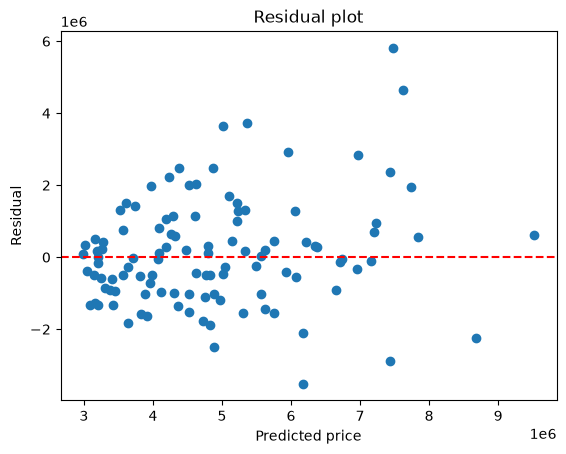

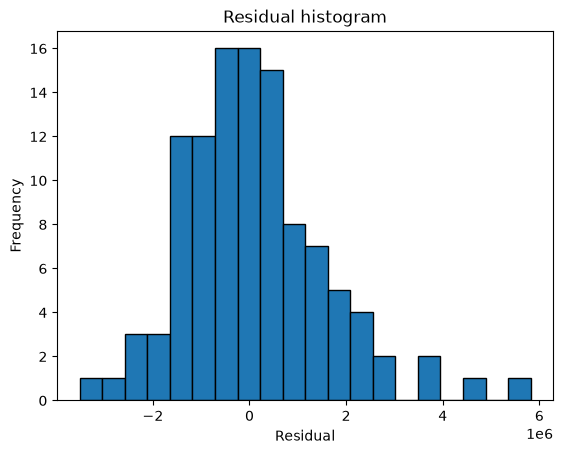

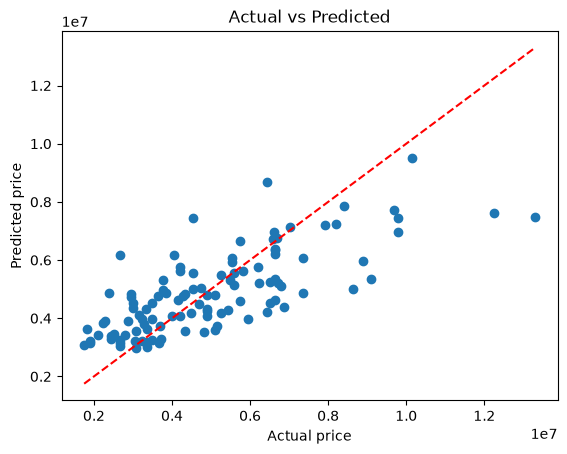

,area,bedrooms,bathrooms,stories,parking
area,1.000000,0.154674,0.199208,0.070472,0.337417
bedrooms,0.154674,1.000000,0.391447,0.405104,0.141470
bathrooms,0.199208,0.391447,1.000000,0.315805,0.194037
stories,0.070472,0.405104,0.315805,1.000000,0.050604
parking,0.337417,0.141470,0.194037,0.050604,1.000000


In [9]:
residual = y_test - pred
plt.scatter(pred, residual); plt.axhline(0, color='red', linestyle='--')
plt.xlabel("Predicted price"); plt.ylabel("Residual"); plt.title("Residual plot"); plt.show()

plt.hist(residual, bins=20, edgecolor='black')
plt.xlabel("Residual"); plt.ylabel("Frequency"); plt.title("Residual histogram"); plt.show()

plt.scatter(y_test, pred)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel("Actual price"); plt.ylabel("Predicted price")
plt.title("Actual vs Predicted"); plt.show()

display(X_train.corr())

In [10]:
vif = []
for col in X_train.columns:
    others = X_train.drop(columns=col)
    r2_aux = LinearRegression().fit(others, X_train[col]).score(others, X_train[col])
    vif.append(1 / (1 - r2_aux) if r2_aux < 1 else np.inf)
display(pd.DataFrame({'Feature': features, 'VIF': vif}))

,Feature,VIF
0,area,1.157790
1,bedrooms,1.332267
2,bathrooms,1.269826
3,stories,1.241431
4,parking,1.154152


In [11]:
new_house = pd.DataFrame([X_train.median().to_dict()], columns=features)
print("New house features:\n", new_house)
print("Predicted price:", multi.predict(new_house)[0])

New house features:
      area  bedrooms  bathrooms  stories  parking
0  4500.0       3.0        1.0      2.0      0.0
Predicted price: 4071574.470116498
